# Tracking Analysis — Third Parties and Tracker Detection

This notebook reproduces and extends the **tracking and third-party analysis** from the paper:

> **The Bitter Pill: Tracking and Remarketing on EU Pharmacy Websites**  

It loads HAR files from the data collection phase, parses requests, resolves CNAMEs for tracker detection, and analyses third-party and tracker prevalence by site, consent mode, and category.

**Data:** Expects HAR files under the path set in `common.BASE_HAR_DIR` (see `common.py`).  
**Dependencies:** `pandas`, `seaborn`, `matplotlib`, `tld`; project modules `utils`, `common`. For tracker detection (uBlock): Node.js and run `npm install` in `notebooks/ublock/` once (see that folder’s README).

## Setup and data load

Imports, plot style, and loading of HAR data into a single dataframe (with CNAME resolution and tracker labelling via `utils`).

**Expected HAR layout:** `BASE_HAR_DIR` must contain subfolders named like `Final_social_it_accept` (four parts: prefix, exp_mode, country, consent).

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from utils import parse_har_files_to_dataframe
from common import BASE_HAR_DIR


sns.set_theme(style="whitegrid", context="paper")
pd.set_option('display.max_colwidth', 128)

# use_cache=False forces reading from BASE_HAR_DIR and prints how many folders/HAR files were found
df = parse_har_files_to_dataframe(BASE_HAR_DIR, test=False, use_cache=False)


### Tracker domains vs third parties
- sanity check to make sure most tracker domains are third-party domains


<Axes: xlabel='is_tracker'>

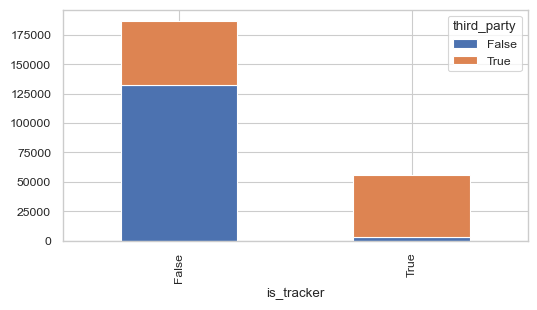

In [21]:
pd.crosstab(df['is_tracker'], df['third_party']).plot(kind='bar', stacked=True, figsize=(6, 3))


- A number of first-party requests are also detected as trackers (e.g. due to parameters and first-party tracking).
- First-party trackers (e.g. SST endpoints) can be included or excluded in aggregate stats depending on the analysis goal.

In [ ]:
# first party requests detected as trackers
df[df.is_tracker & ~df.third_party].\
    drop_duplicates(subset=['site_hostname', 'req_hostname'])[
        ['site_hostname', 'req_hostname', 'url']].head(10)

### Tracker categories (purposes)

<Axes: ylabel='categories'>

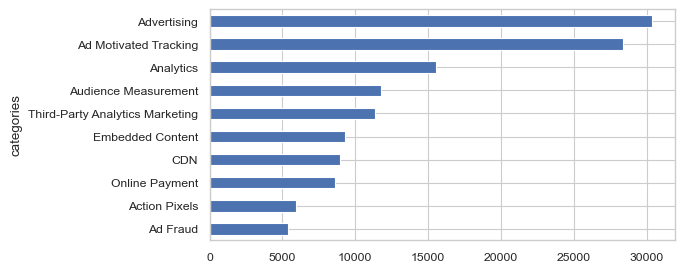

In [22]:
df[df.is_tracker].explode('categories')['categories'].\
    value_counts(ascending=True).tail(10).plot(kind='barh', figsize=(6, 3))

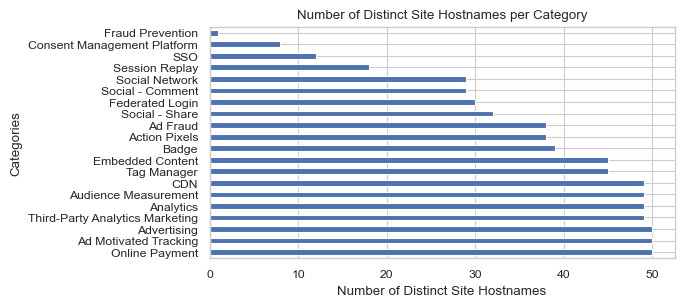

In [8]:
df[(df.exp_mode == 'tracking') & df.is_tracker].\
    explode('categories').groupby('categories')['site_hostname'].nunique().\
        sort_values(ascending=False).plot(kind='barh', figsize=(6, 3))
plt.xlabel('Number of Distinct Site Hostnames')
plt.ylabel('Categories')
plt.title('Number of Distinct Site Hostnames per Category')
plt.show()

### Tracker domains

In [ ]:
sorted(df[df.is_tracker].req_domain.unique().tolist())


### Median number of third-party domains per site

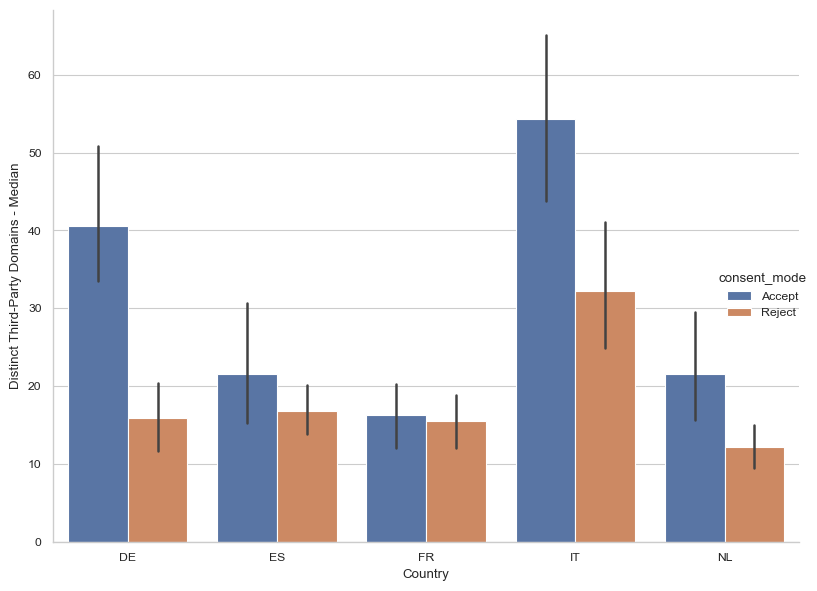

In [10]:

GROUP_COLS = ['exp_mode', 'consent_mode', 'country', 'site_domain']

df_median = df[df.third_party].groupby(GROUP_COLS)['req_domain'] \
                   .nunique() \
                   .groupby(GROUP_COLS) \
                   .median() \
                   .reset_index(name='median_req_domains')

# Convert the 'median_req_domains' column to integers
df_median['median_req_domains'] = df_median['median_req_domains'].astype(int)

df_median_t = df_median[df_median.exp_mode == 'tracking']
df_median_s = df_median[df_median.exp_mode == 'social']

sns.catplot(data=df_median_t, x='country', y='median_req_domains',
            hue='consent_mode', kind='bar', height=6, aspect=1.2)

# Add labels and title
# plt.title('Median Distinct Third-party Domains by Country and Consent Mode')
plt.ylabel('Distinct Third-Party Domains - Median')
plt.xlabel('Country')
# plt.legend(title='Consent Mode')

# Show the plot
plt.tight_layout()
plt.show()


### Median number of third-party domains per site (Social data)

Text(0.5, 26.790625000000034, 'Country')

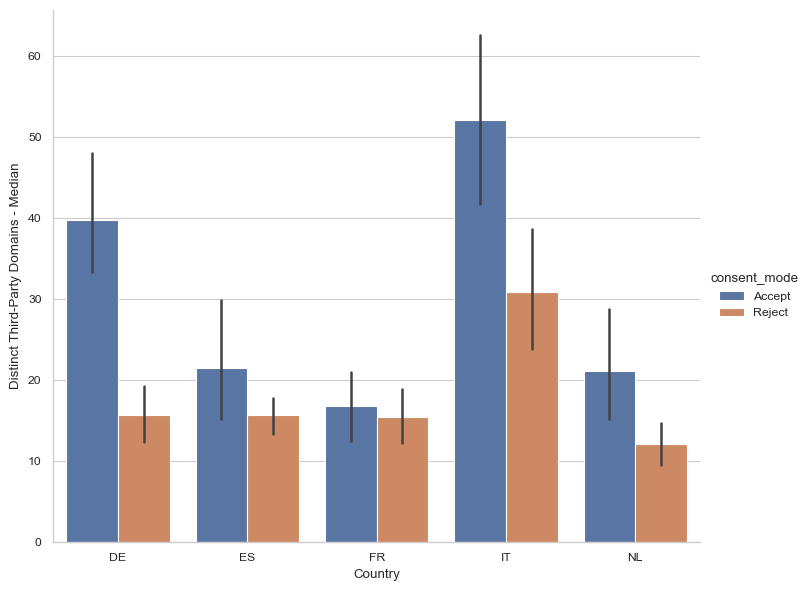

In [11]:
# Note: data from the social exp.
sns.catplot(data=df_median_s, x='country', y='median_req_domains',
            hue='consent_mode', kind='bar', height=6, aspect=1.2)

plt.ylabel('Distinct Third-Party Domains - Median')
plt.xlabel('Country')


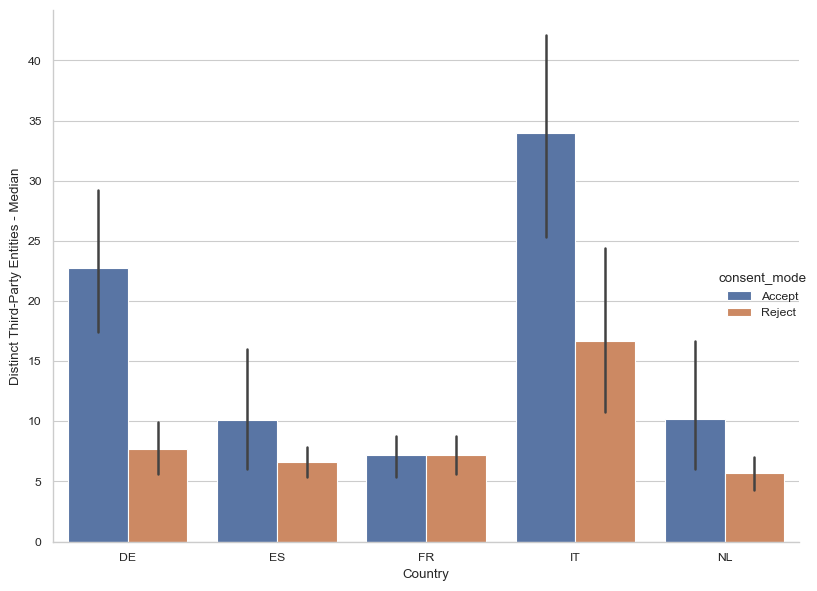

In [12]:

GROUP_COLS = ['exp_mode', 'consent_mode', 'country', 'site_domain']

df_median = df[df.third_party].groupby(GROUP_COLS)['entity'] \
                   .nunique() \
                   .groupby(GROUP_COLS) \
                   .median() \
                   .reset_index(name='median_entities')

# Convert the 'median_req_domains' column to integers
df_median['median_entities'] = df_median['median_entities'].astype(int)

df_median_t = df_median[df_median.exp_mode == 'tracking']
df_median_s = df_median[df_median.exp_mode == 'social']

sns.catplot(data=df_median_t, x='country', y='median_entities',
            hue='consent_mode', kind='bar', height=6, aspect=1.2)

# Add labels and title
# plt.title('Median Distinct Third-party Domains by Country and Consent Mode')
plt.ylabel('Distinct Third-Party Entities - Median')
plt.xlabel('Country')
# plt.legend(title='Consent Mode')

# Show the plot
plt.tight_layout()
plt.show()


## Focus on "Tracking" experiment

In [14]:
df_t = df[df['exp_mode'] == 'tracking']

### Number of third-party domains per site

In [ ]:
# distinct third-party req_domain's by consent_mode, exp_mode, country, site_domain
df_t[df_t.third_party].\
    groupby(['consent_mode', 'country', 'site_domain'])['req_domain'].\
    nunique().to_frame()

### Number of third-party entities per site

In [ ]:
# distinct third-party req_domain's by consent_mode, exp_mode, country, site_domain
df_t[df_t.third_party].\
    groupby(['consent_mode', 'country', 'site_domain'])['entity'].\
    nunique().to_frame()

### Accept vs Reject - Top 10 third-party domains

In [ ]:

tmp_df = df_t.pivot_table(
    index='req_domain',                  # Rows: Unique request domains
    columns='consent_mode',           # Columns: Consent mode (accepted/rejected)
    values='site_domain',                # Values: Count of unique site domains
    aggfunc='nunique',                   # Aggregate function: Count unique site domains
    fill_value=0                          # Fill missing values with 0
)

tmp_df.sort_values(by='Accept', ascending=False).head(10)

### Accept vs Reject - Top 10 third-party entities

In [ ]:

table = df_t[df_t.entity != ''].pivot_table(
    index='entity',                  # Rows: Unique entity names
    columns='consent_mode',           # Columns: Consent mode (accepted/rejected)
    values='site_domain',                # Values: Count of unique site domains
    aggfunc='nunique',                   # Aggregate function: Count unique site domains
    fill_value=0                          # Fill missing values with 0
)

# Optionally sort the results if needed
table.sort_values(by='Accept', ascending=False).head(10)

### Close look on site with most third-party domains

In [ ]:
df_t[df_t.site_domain == 'sanicare.de']['entity'].unique()